# Startup Outcome Classifier (fixed, memory-safe version)

Predicts whether a startup ends up **Closed (0)** or **Operating / Acquired / IPO (1)**.

**What was fixed compared to the previous notebook**
- **Out-of-memory crash (Step 9):** `permalink`, `homepage_url`, `category_list`, `city`, `region`, the raw date columns and `funding_total_usd` (stored as text) were one-hot encoded into a *dense* matrix with 100k+ columns. They are now converted into compact numeric features and a few capped categoricals, and one-hot output is sparse.
- **Syntax error** in the save cell (`joblib.dump(...))`).
- One preprocessor object was shared and refit by three models. Each model now has its own.
- The 90/10 class imbalance is now handled and evaluated with metrics that are not fooled by it.
- Hard-coded `/content` paths were replaced by auto-detection (Kaggle, Colab or local).
- Duplicated load cells and the duplicate "Step 1" were removed.

### Step 1: Install & import libraries

In [1]:
try:
    import catboost
except ImportError:
    %pip install -q catboost

In [2]:
import os, gc, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from catboost import CatBoostClassifier

warnings.filterwarnings('ignore')
RANDOM_SEED = 42

# Works on Kaggle, Colab, or locally
OUT_DIR = '/kaggle/working' if os.path.isdir('/kaggle/working') else '.'
os.makedirs(OUT_DIR, exist_ok=True)

try:
    import psutil
    def mem(tag=''):
        print(f"[memory] {tag}: {psutil.Process().memory_info().rss / 1e9:.2f} GB in use by this notebook")
except ImportError:
    def mem(tag=''):
        pass

mem('start')

[memory] start: 0.30 GB in use by this notebook


### Step 2: Load the dataset and inspect the target column

In [3]:
# Exact location shown in the Kaggle sidebar (Input > Datasets)
DATASET_DIR  = '/kaggle/input/big_startup_secsees_dataset'
DATASET_FILE = 'big_startup_secsees_dataset.csv'
csv_path = os.path.join(DATASET_DIR, DATASET_FILE)

if not os.path.exists(csv_path):
    # Fallback: search in case the dataset folder was renamed (Kaggle / Colab / local)
    print(f"Not found at {csv_path}. Searching...")
    candidates = []
    for root in ['/kaggle/input', '/content', '.']:
        candidates += glob.glob(os.path.join(root, '**', DATASET_FILE), recursive=True)
    if not candidates:
        print("Files visible under /kaggle/input:")
        for p in glob.glob('/kaggle/input/**/*', recursive=True):
            print("  ", p)
        raise FileNotFoundError(f"{DATASET_FILE} not found. Use 'Add Input' in the right sidebar to attach the dataset.")
    csv_path = candidates[0]

print("Using:", csv_path)

df = pd.read_csv(csv_path)
print(f"Dataset shape: {df.shape}")
display(df.head())
df.info()
print("\nMissing values:\n", df.isnull().sum())

print("\nStatus distribution:")
display(df['status'].value_counts(dropna=False))

Not found at /kaggle/input/big_startup_secsees_dataset/big_startup_secsees_dataset.csv. Searching...
Using: /kaggle/input/datasets/mananpatel7310/big-startup-secsees-dataset/big_startup_secsees_dataset.csv
Dataset shape: (66368, 14)


,permalink,name,homepage_url,category_list,funding_total_usd,status,country_code,state_code,region,city,funding_rounds,founded_at,first_funding_at,last_funding_at
0,/organization/-fame,#fame,http://livfame.com,Media,10000000,operating,IND,16,Mumbai,Mumbai,1,NaN,2015-01-05,2015-01-05
1,/organization/-qounter,:Qounter,http://www.qounter.com,Application Platforms|Real Time|Social Network...,700000,operating,USA,DE,DE - Other,Delaware City,2,2014-09-04,2014-03-01,2014-10-14
2,/organization/-the-one-of-them-inc-,"(THE) ONE of THEM,Inc.",http://oneofthem.jp,Apps|Games|Mobile,3406878,operating,NaN,NaN,NaN,NaN,1,NaN,2014-01-30,2014-01-30
3,/organization/0-6-com,0-6.com,http://www.0-6.com,Curated Web,2000000,operating,CHN,22,Beijing,Beijing,1,2007-01-01,2008-03-19,2008-03-19
4,/organization/004-technologies,004 Technologies,http://004gmbh.de/en/004-interact,Software,-,operating,USA,IL,"Springfield, Illinois",Champaign,1,2010-01-01,2014-07-24,2014-07-24


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 66368 entries, 0 to 66367
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   permalink          66368 non-null  object
 1   name               66367 non-null  object
 2   homepage_url       61310 non-null  object
 3   category_list      63220 non-null  object
 4   funding_total_usd  66368 non-null  object
 5   status             66368 non-null  object
 6   country_code       59410 non-null  object
 7   state_code         57821 non-null  object
 8   region             58338 non-null  object
 9   city               58340 non-null  object
 10  funding_rounds     66368 non-null  int64 
 11  founded_at         51147 non-null  object
 12  first_funding_at   66344 non-null  object
 13  last_funding_at    66368 non-null  object
dtypes: int64(1), object(13)
memory usage: 7.1+ MB

Missing values:
 permalink                0
name                     1
homepage_url    

status
operating    53034
closed        6238
acquired      5549
ipo           1547
Name: count, dtype: int64

### Step 3: Build the binary target and clean the data
`0 = closed`, `1 = operating / acquired / ipo`. Duplicates are removed by company (`permalink`).

Shape after cleaning: (66368, 15)
target
1    60130
0     6238
Name: count, dtype: int64
target
1    0.906
0    0.094
Name: proportion, dtype: float64


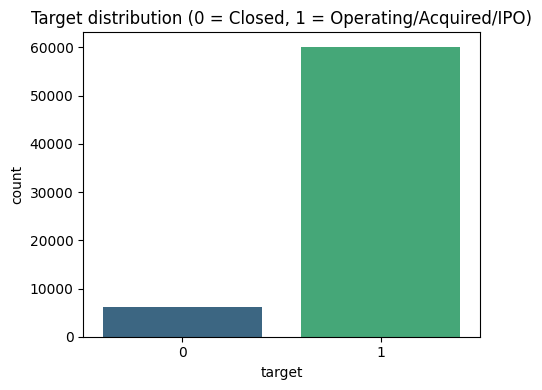

In [4]:
mapping = {'closed': 0, 'operating': 1, 'acquired': 1, 'ipo': 1}
df = df.dropna(subset=['status']).copy()
df['target'] = df['status'].str.strip().str.lower().map(mapping)
df = df.dropna(subset=['target'])
df['target'] = df['target'].astype(int)

df = df.drop_duplicates(subset='permalink').reset_index(drop=True)
print("Shape after cleaning:", df.shape)
print(df['target'].value_counts())
print(df['target'].value_counts(normalize=True).round(3))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x='target', palette='viridis', ax=ax)
ax.set_title('Target distribution (0 = Closed, 1 = Operating/Acquired/IPO)')
plt.tight_layout(); plt.show()

### Step 4: Why the old pipeline ran out of memory
Number of **distinct values per column**. One-hot encoding creates one column per distinct value, so ID-like and free-text columns explode the matrix size.

In [5]:
cardinality = df.drop(columns=['target']).nunique().sort_values(ascending=False)
display(cardinality.to_frame('distinct_values'))

old_cols = int(cardinality.drop(['status'], errors='ignore').sum())
print(f"\nOld approach: ~{old_cols:,} one-hot columns x {int(len(df) * 0.7):,} rows "
      f"x 8 bytes = ~{old_cols * int(len(df) * 0.7) * 8 / 1e9:,.0f} GB (dense). That is why the kernel died.")

,distinct_values
permalink,66368
name,66102
homepage_url,61191
category_list,27296
funding_total_usd,18896
city,5111
first_funding_at,4817
last_funding_at,4518
founded_at,3978
region,1092



Old approach: ~259,836 one-hot columns x 46,457 rows x 8 bytes = ~97 GB (dense). That is why the kernel died.


### Step 5: Feature engineering (stateless, row-wise, so there is no leakage)
The feature code lives in a small module (`startup_features.py`) so that the saved model can be used later in any session.

- Dropped: `permalink`, `name` (identifiers), `status` / `target` (the label itself).
- `homepage_url` becomes a `has_homepage` flag.
- `funding_total_usd` (text such as `-`) becomes a numeric value plus a log version and a missing flag.
- Dates become years and durations.
- `category_list` becomes the primary category plus the number of categories.

In [6]:
%%writefile startup_features.py
import numpy as np
import pandas as pd

RAW_COLS = ['homepage_url', 'category_list', 'funding_total_usd', 'country_code', 'state_code',
            'region', 'city', 'funding_rounds', 'founded_at', 'first_funding_at', 'last_funding_at']

NUM_COLS = ['funding_rounds', 'funding_total', 'funding_total_log', 'funding_missing',
            'funding_per_round', 'founded_year', 'first_funding_year', 'last_funding_year',
            'years_to_first_funding', 'funding_span_years', 'n_categories', 'has_homepage']

CAT_COLS = ['country_code', 'state_code', 'region', 'city', 'primary_category']

FEATURE_COLS = NUM_COLS + CAT_COLS


def engineer_features(df):
    df = df.reindex(columns=RAW_COLS)
    out = pd.DataFrame(index=df.index)

    funding = pd.to_numeric(
        df['funding_total_usd'].astype(str).str.replace(r'[^0-9.]', '', regex=True),
        errors='coerce')
    rounds = pd.to_numeric(df['funding_rounds'], errors='coerce')

    out['funding_rounds'] = rounds
    out['funding_total'] = funding
    out['funding_total_log'] = np.log1p(funding)
    out['funding_missing'] = funding.isna().astype(int)
    out['funding_per_round'] = funding / rounds.replace(0, np.nan)

    founded = pd.to_datetime(df['founded_at'], errors='coerce')
    first = pd.to_datetime(df['first_funding_at'], errors='coerce')
    last = pd.to_datetime(df['last_funding_at'], errors='coerce')
    out['founded_year'] = founded.dt.year
    out['first_funding_year'] = first.dt.year
    out['last_funding_year'] = last.dt.year
    out['years_to_first_funding'] = (first - founded).dt.days / 365.25
    out['funding_span_years'] = (last - first).dt.days / 365.25

    cats = df['category_list'].fillna('').astype(str).str.strip('|')
    out['n_categories'] = cats.apply(lambda s: len([c for c in s.split('|') if c]))
    out['primary_category'] = cats.str.split('|').str[0].replace('', 'missing')
    out['has_homepage'] = df['homepage_url'].notna().astype(int)

    for c in ['country_code', 'state_code', 'region', 'city']:
        out[c] = df[c]
    for c in CAT_COLS:
        out[c] = out[c].fillna('missing').astype(str)

    num = out[NUM_COLS].astype(float).replace([np.inf, -np.inf], np.nan)
    out[NUM_COLS] = num
    return out[FEATURE_COLS]

Writing startup_features.py


In [7]:
from startup_features import engineer_features, RAW_COLS, NUM_COLS, CAT_COLS, FEATURE_COLS

X = engineer_features(df)
y = df['target']

print("Feature matrix:", X.shape)
display(X.head())
print("\nDistinct values of categorical features:")
print(X[CAT_COLS].nunique())
mem('after feature engineering')

Feature matrix: (66368, 17)


,funding_rounds,funding_total,funding_total_log,funding_missing,funding_per_round,founded_year,first_funding_year,last_funding_year,years_to_first_funding,funding_span_years,n_categories,has_homepage,country_code,state_code,region,city,primary_category
0,1.0,10000000.0,16.118096,0.0,10000000.0,NaN,2015.0,2015.0,NaN,0.000000,1.0,1.0,IND,16,Mumbai,Mumbai,Media
1,2.0,700000.0,13.458837,0.0,350000.0,2014.0,2014.0,2014.0,-0.511978,0.621492,3.0,1.0,USA,DE,DE - Other,Delaware City,Application Platforms
2,1.0,3406878.0,15.041307,0.0,3406878.0,NaN,2014.0,2014.0,NaN,0.000000,3.0,1.0,missing,missing,missing,missing,Apps
3,1.0,2000000.0,14.508658,0.0,2000000.0,2007.0,2008.0,2008.0,1.212868,0.000000,1.0,1.0,CHN,22,Beijing,Beijing,Curated Web
4,1.0,NaN,NaN,1.0,NaN,2010.0,2014.0,2014.0,4.558522,0.000000,1.0,1.0,USA,IL,"Springfield, Illinois",Champaign,Software



Distinct values of categorical features:
country_code         138
state_code           312
region              1093
city                5112
primary_category     729
dtype: int64
[memory] after feature engineering: 0.39 GB in use by this notebook


### Step 6: Stratified Train / Validation / Test split (70 / 15 / 15)

In [8]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, random_state=RANDOM_SEED, stratify=y)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.15 / 0.85, random_state=RANDOM_SEED, stratify=y_train_val)

print(f"Train: {X_train.shape} | Validation: {X_val.shape} | Test: {X_test.shape}")
print("Closed share  train/val/test:",
      round((y_train == 0).mean(), 3), round((y_val == 0).mean(), 3), round((y_test == 0).mean(), 3))

del X_train_val, y_train_val
gc.collect()

Train: (46456, 17) | Validation: (9956, 17) | Test: (9956, 17)
Closed share  train/val/test: 0.094 0.094 0.094


72

### Step 7: Train baseline models (Logistic Regression, Random Forest)
Key memory fixes:
- one-hot output is **sparse**;
- rare categories are grouped via `min_frequency`, so the number of columns stays small;
- every model gets its **own** preprocessor (the old code shared and refit one object);
- `class_weight` compensates for the 90/10 imbalance.

In [9]:
def make_preprocessor():
    num_transformer = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])
    cat_transformer = OneHotEncoder(handle_unknown='infrequent_if_exist',
                                    min_frequency=30, sparse_output=True)
    return ColumnTransformer([
        ('num', num_transformer, NUM_COLS),
        ('cat', cat_transformer, CAT_COLS)
    ])

lr_model = Pipeline([
    ('preprocessor', make_preprocessor()),
    ('classifier', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_SEED))
])

rf_model = Pipeline([
    ('preprocessor', make_preprocessor()),
    ('classifier', RandomForestClassifier(n_estimators=200, max_depth=20, min_samples_leaf=3,
                                          class_weight='balanced_subsample',
                                          n_jobs=-1, random_state=RANDOM_SEED))
])

print("Training Logistic Regression...")
lr_model.fit(X_train, y_train)
n_cols = lr_model.named_steps['preprocessor'].transform(X_train.head(5)).shape[1]
print(f"  encoded feature count: {n_cols:,} (was 100,000+ before)")
mem('after logistic regression')

print("Training Random Forest...")
rf_model.fit(X_train, y_train)
mem('after random forest')
gc.collect()

Training Logistic Regression...
  encoded feature count: 712 (was 100,000+ before)
[memory] after logistic regression: 0.42 GB in use by this notebook
Training Random Forest...
[memory] after random forest: 0.42 GB in use by this notebook


47

### Step 8: Train CatBoost
CatBoost handles categorical text columns **natively**, so no one-hot encoding is needed, and early stopping uses the validation set.

In [10]:
print("Training CatBoost with early stopping...")
cat_model = CatBoostClassifier(
    iterations=600,
    learning_rate=0.05,
    depth=6,
    eval_metric='AUC',
    auto_class_weights='Balanced',
    random_seed=RANDOM_SEED,
    early_stopping_rounds=50,
    thread_count=-1,
    allow_writing_files=False,
    verbose=100
)
cat_model.fit(X_train, y_train, cat_features=CAT_COLS, eval_set=(X_val, y_val), use_best_model=True)
print("Best iteration:", cat_model.get_best_iteration())
mem('after catboost')
gc.collect()

Training CatBoost with early stopping...
0:	test: 0.7413652	best: 0.7413652 (0)	total: 126ms	remaining: 1m 15s
100:	test: 0.7973681	best: 0.7973686 (96)	total: 5.04s	remaining: 24.9s
200:	test: 0.8006362	best: 0.8006362 (200)	total: 9.78s	remaining: 19.4s
300:	test: 0.8031750	best: 0.8034327 (289)	total: 14.8s	remaining: 14.7s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.8034327207
bestIteration = 289

Shrink model to first 290 iterations.
Best iteration: 289
[memory] after catboost: 0.61 GB in use by this notebook


0

### Step 9: Compare models on the validation set
With ~90% positives, accuracy is misleading. We also report the **closed-class** precision / recall / F1 and PR-AUC.

In [11]:
models = {'Logistic Regression': lr_model, 'Random Forest': rf_model, 'CatBoost': cat_model}

def evaluate(model, X_eval, y_eval):
    preds = np.asarray(model.predict(X_eval)).ravel().astype(int)
    probs = model.predict_proba(X_eval)[:, 1]
    return {
        'Accuracy': accuracy_score(y_eval, preds),
        'ROC-AUC': roc_auc_score(y_eval, probs),
        'PR-AUC (closed)': average_precision_score(1 - y_eval, 1 - probs),
        'Precision (closed)': precision_score(y_eval, preds, pos_label=0),
        'Recall (closed)': recall_score(y_eval, preds, pos_label=0),
        'F1 (closed)': f1_score(y_eval, preds, pos_label=0),
        'F1 (macro)': f1_score(y_eval, preds, average='macro'),
    }

results_df = pd.DataFrame([{'Model': n, **evaluate(m, X_val, y_val)} for n, m in models.items()])
results_df = results_df.set_index('Model').round(4)
display(results_df)

best_name = results_df['ROC-AUC'].idxmax()
best_model = models[best_name]
print(f"Selected champion model (highest validation ROC-AUC): {best_name}")

,Accuracy,ROC-AUC,PR-AUC (closed),Precision (closed),Recall (closed),F1 (closed),F1 (macro)
Model,,,,,,,
Logistic Regression,0.7095,0.7470,0.2623,0.1940,0.6624,0.3001,0.5584
Random Forest,0.7482,0.7960,0.3196,0.2256,0.6902,0.3401,0.5923
CatBoost,0.7136,0.8034,0.3345,0.2112,0.7479,0.3293,0.5736


Selected champion model (highest validation ROC-AUC): CatBoost


### Step 10: Final evaluation of the champion on the untouched test set

Test results for CatBoost:


,Test
Accuracy,0.7226
ROC-AUC,0.8203
PR-AUC (closed),0.3579
Precision (closed),0.2189
Recall (closed),0.7596
F1 (closed),0.3399
F1 (macro),0.5821


              precision    recall  f1-score   support

  Closed (0)       0.22      0.76      0.34       936
 Success (1)       0.97      0.72      0.82      9020

    accuracy                           0.72      9956
   macro avg       0.59      0.74      0.58      9956
weighted avg       0.90      0.72      0.78      9956



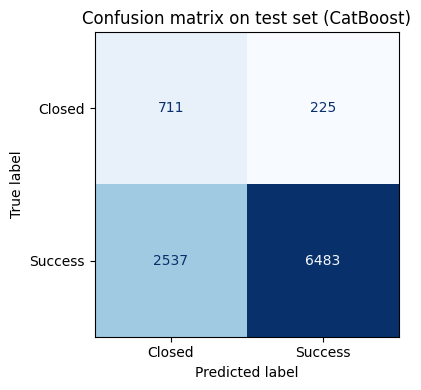

In [12]:
test_metrics = evaluate(best_model, X_test, y_test)
print(f"Test results for {best_name}:")
display(pd.Series(test_metrics).round(4).to_frame('Test'))

test_preds = np.asarray(best_model.predict(X_test)).ravel().astype(int)
print(classification_report(y_test, test_preds, target_names=['Closed (0)', 'Success (1)']))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, test_preds),
                       display_labels=['Closed', 'Success']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Confusion matrix on test set ({best_name})')
plt.tight_layout(); plt.show()

### Step 11: Feature importance (CatBoost)
Because CatBoost uses the real feature names, importances are directly readable. There are no thousands of one-hot columns.

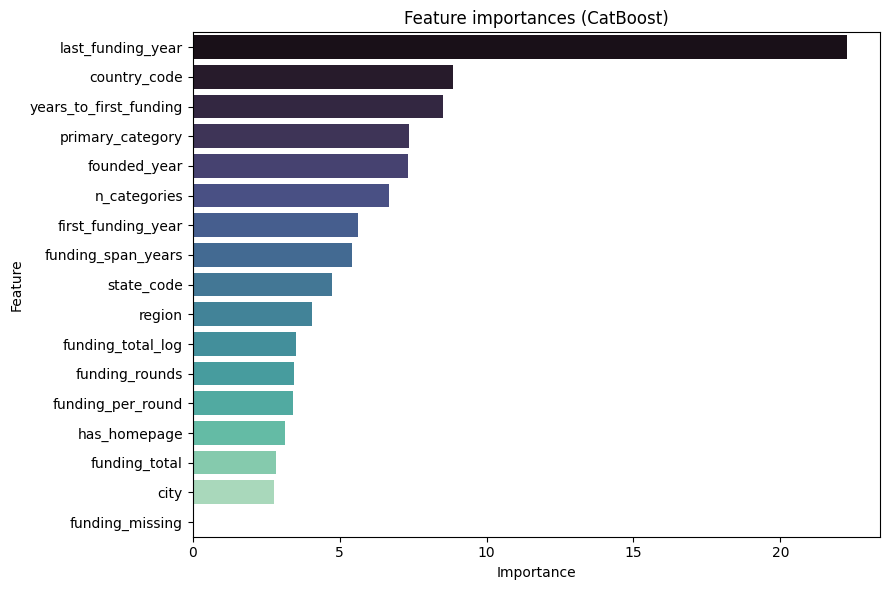

In [13]:
feat_imp_df = (pd.DataFrame({'Feature': cat_model.feature_names_,
                             'Importance': cat_model.get_feature_importance()})
               .sort_values('Importance', ascending=False))

plt.figure(figsize=(9, 6))
sns.barplot(data=feat_imp_df, x='Importance', y='Feature', palette='mako')
plt.title('Feature importances (CatBoost)')
plt.tight_layout(); plt.show()

### Step 12: Save the champion model

In [14]:
model_path = os.path.join(OUT_DIR, 'startup_outcome_classifier.pkl')
artifact = {
    'model': best_model,
    'model_name': best_name,
    'raw_columns': RAW_COLS,
    'feature_columns': FEATURE_COLS,
}
joblib.dump(artifact, model_path)
print(f"Saved to {model_path} ({os.path.getsize(model_path) / 1e6:.1f} MB)")
print("To reuse the model elsewhere, keep startup_features.py next to the .pkl file.")

Saved to /kaggle/working/startup_outcome_classifier.pkl (13.8 MB)
To reuse the model elsewhere, keep startup_features.py next to the .pkl file.


### Step 13: Prediction function and sanity test
Takes a dataframe with the **raw** dataset columns (as in the CSV) and returns the class and the probabilities.

In [15]:
def predict_startup_outcome(input_df, path=model_path):
    """Raw startup rows in -> (class 0/1, probability of class 0, probability of class 1)."""
    from startup_features import engineer_features
    art = joblib.load(path)
    feats = engineer_features(input_df.reindex(columns=art['raw_columns']))
    model = art['model']
    preds = np.asarray(model.predict(feats)).ravel().astype(int)
    probs = model.predict_proba(feats)
    return preds, probs

raw_test_rows = df.loc[X_test.index[:3]]
sample_pred, sample_prob = predict_startup_outcome(raw_test_rows)
for i, idx in enumerate(raw_test_rows.index):
    actual = int(df.loc[idx, 'target'])
    print(f"Row {idx}: predicted={sample_pred[i]} | actual={actual} | "
          f"P(closed)={sample_prob[i][0]:.3f}, P(success)={sample_prob[i][1]:.3f}")
mem('end')

Row 12029: predicted=0 | actual=1 | P(closed)=0.520, P(success)=0.480
Row 30027: predicted=0 | actual=1 | P(closed)=0.579, P(success)=0.421
Row 13217: predicted=1 | actual=1 | P(closed)=0.129, P(success)=0.871
[memory] end: 0.64 GB in use by this notebook
